In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:
# Load a new dataset more suitable for linear regression (continuous target)
import pandas as pd
from sklearn.datasets import load_diabetes

# Fetch dataset
df_new = pd.read_csv("diabetes_dataset_processed.csv")

# Display the first 5 rows and column information to help choose X and Y
print("Loaded data head:")
display(df_new.head())
print("\nColumn information:")
display(df_new.info())

# --- Defining X and Y for the new dataset ---
x_column_new = 's5'
y_column_new = 'target'

# Extract X and Y. Ensure X is reshaped for scikit-learn.
X = df_new[[x_column_new]].values
Y = df_new[y_column_new].values.reshape(-1, 1)

Loaded data head:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


None

In [ ]:
model = LinearRegression()
model.fit(X, Y)

LinearRegression()

In [ ]:
# Get the intercept and coefficients
print(f"Intercept: {model.intercept_[0]:.2f}")
print(f"Coefficient: {model.coef_[0][0]:.2f}")

Intercept: 152.13
Coefficient: 916.14


In [ ]:
# Make predictions
Y_pred = model.predict(X)

In [ ]:
from sklearn.metrics import mean_squared_error

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(Y, Y_pred)
print(f"Mean Squared Error (MSE): {mse:.2f}")

Mean Squared Error (MSE): 4031.00


In [ ]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r_squared = r2_score(Y, Y_pred)
print(f"R-squared (R2) Score: {r_squared:.2f}")

R-squared (R2) Score: 0.32


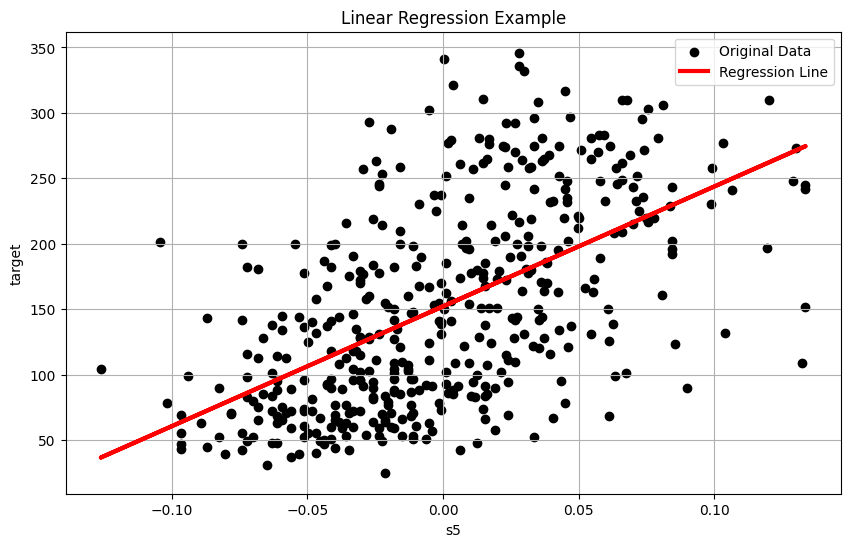

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X, Y, color='black', label='Original Data')
plt.plot(X, Y_pred, color='red', linewidth=3, label='Regression Line')
plt.title('Linear Regression Example')
plt.xlabel(x_column_new)
plt.ylabel(y_column_new)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# --- Defining X and Y for Multiple Linear Regression ---
x_columns_multiple = ['age', 'bmi', 's5'] # Using multiple features for X
y_column_multiple = 'target'

# Extract X and Y for multiple regression
X_multiple = df_new[x_columns_multiple].values
Y_multiple = df_new[y_column_multiple].values.reshape(-1, 1)

print(f"X_multiple shape: {X_multiple.shape}")
print(f"Y_multiple shape: {Y_multiple.shape}")

X_multiple shape: (442, 3)
Y_multiple shape: (442, 1)


In [ ]:
# Create and fit the Multiple Linear Regression model
model_multiple = LinearRegression()
model_multiple.fit(X_multiple, Y_multiple)

print("Multiple Linear Regression Model Fitted.")

Multiple Linear Regression Model Fitted.


In [ ]:
# Get the intercept and coefficients for the multiple regression model
print(f"Multiple Regression Intercept: {model_multiple.intercept_[0]:.2f}")

# Print coefficients for each feature
for i, col in enumerate(x_columns_multiple):
    print(f"Coefficient for '{col}': {model_multiple.coef_[0][i]:.2f}")

Multiple Regression Intercept: 152.13
Coefficient for 'age': 13.81
Coefficient for 'bmi': 673.96
Coefficient for 's5': 611.71


In [ ]:
# Make predictions with the multiple linear regression model
Y_pred_multiple = model_multiple.predict(X_multiple)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate Mean Squared Error (MSE) for multiple regression
mse_multiple = mean_squared_error(Y_multiple, Y_pred_multiple)
print(f"Mean Squared Error (MSE) for Multiple Regression: {mse_multiple:.2f}")

# Calculate R-squared score for multiple regression
r_squared_multiple = r2_score(Y_multiple, Y_pred_multiple)
print(f"R-squared (R2) Score for Multiple Regression: {r_squared_multiple:.2f}")

Mean Squared Error (MSE) for Multiple Regression: 3204.79
R-squared (R2) Score for Multiple Regression: 0.46


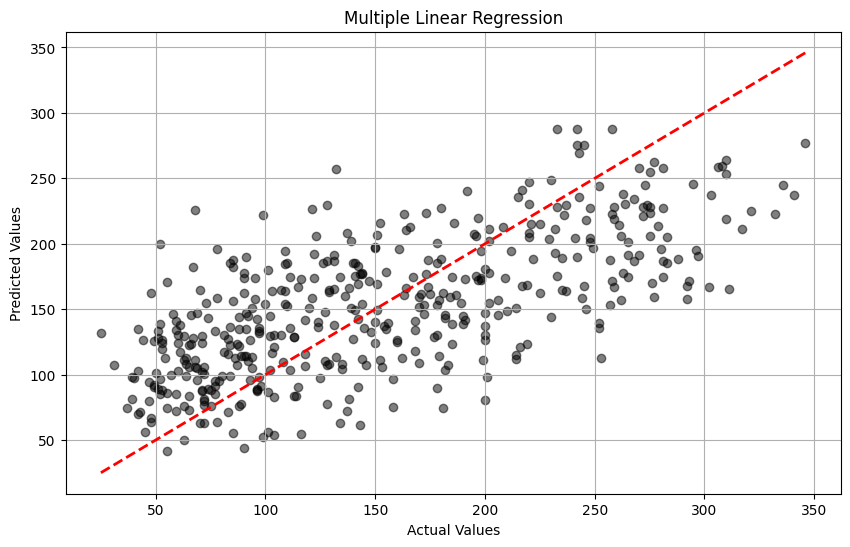

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(Y_multiple, Y_pred_multiple, color = "black",alpha=0.5)
plt.plot([Y_multiple.min(), Y_multiple.max()], [Y_multiple.min(), Y_multiple.max()], 'r--', lw=2)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Multiple Linear Regression")
plt.grid(True)
plt.show()